# Benchmark 1: Pitchfork Bifurcation

Supercritical pitchfork normal form, bifurcation at $\mu=0$:
$$\dot{u} = f(u, \mu) = -u^3 + \mu u$$

1. Oscillating roots vs. branch-approximating solutions by degree continuation.
2. Convergence of the upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ in the smooth, boundary-singularity, and interior-singularity regimes.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_2d, plot_convergence

set_plot_style(usetex=True)

def rhs(u, mu):
    return -u**3 + mu[None, :] * u

def jac(u, mu):
    return (-3.0 * u**2 + mu[None, :])[None, :, :]

def exact_upper(mu):
    return np.sqrt(np.maximum(mu, 0.0))[None, :]

## 1. Oscillating roots and degree continuation

Random coefficient initializations produce oscillating solutions, while degree continuation isolates the branch-approximating solutions.

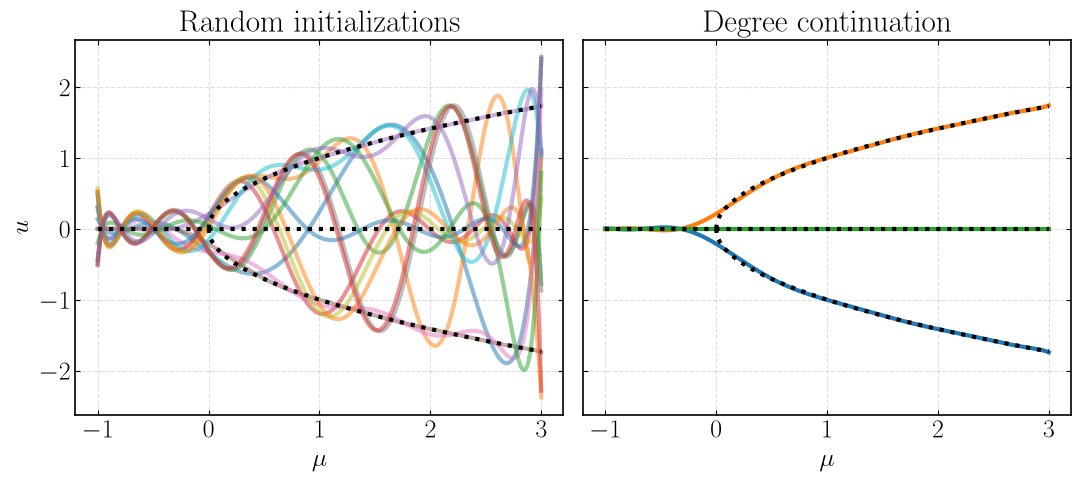

In [2]:
mu_bounds = (-1.0, 3.0)
N = 10
solver = PCEGalerkin(rhs, jac, mu_bounds=mu_bounds, state_dim=1, quad_order=2 * N + 1)
all_roots = solver.random_roots(N, n_samples=20, seed=2, scale=0.8)
branches = solver.find_branches(N, n_samples=20, seed=2, unique_tol=1e-6, box=(-2.0, 2.0))

mu_all = np.linspace(mu_bounds[0], mu_bounds[1], 400)
mu_pos = np.linspace(0.0, mu_bounds[1], 300)
exact = [(mu_all, np.zeros_like(mu_all)), (mu_pos, np.sqrt(mu_pos)), (mu_pos, -np.sqrt(mu_pos))]

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
plot_2d(solver, all_roots, exact, branch_style="-", branch_lw=3.0, branch_zorder=2,
        branch_alpha=0.5, exact_style="k:", exact_lw=3.0, exact_zorder=5,
        title="Random initializations", ax=axes[0])
plot_2d(solver, branches, exact, branch_style="-", branch_lw=3.0, branch_zorder=2,
        exact_style="k:", exact_lw=3.0, exact_zorder=5, ylabel=None,
        title="Degree continuation", ax=axes[1])
plt.tight_layout()
plt.show()

## 2. Convergence across regularity regimes

Upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ on three regimes:
- Smooth: $I = [0.2, 1]$
- Boundary singularity: $I = [0, 1]$
- Interior singularity: $I = [-1, 3]$

### 2.1 Smooth regime

Estimated rho (linf): 2.8029


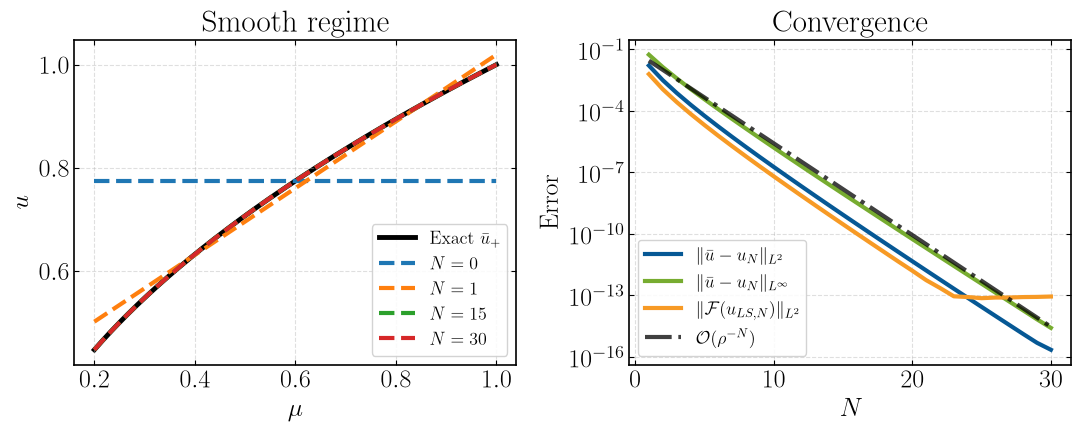

In [3]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]
solver = PCEGalerkin(rhs, jac, mu_bounds=(0.2, 1.0), state_dim=1, quad_order=2 * N_max + 1)
history = solver.continuation(N_max, u0=[1.0], return_history=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
mu_ex = np.linspace(0.2, 1.0, 600)
plot_2d(solver, [history[N] for N in plot_degrees], [(mu_ex, exact_upper(mu_ex))],
        branch_labels=[rf"$N={N}$" for N in plot_degrees], branch_lw=3.0,
        exact_lw=3.5, exact_label=r"Exact $\bar{u}_+$", title="Smooth regime", ax=axes[0])
axes[0].legend(loc="lower right", framealpha=0.85)
plot_convergence(solver, history, exact_upper, ref_rates=[(r"$\mathcal{O}(\rho^{-N})$", "-.", None, "linf")], ax=axes[1])
plt.tight_layout()
plt.show()

### 2.2 Boundary singularity

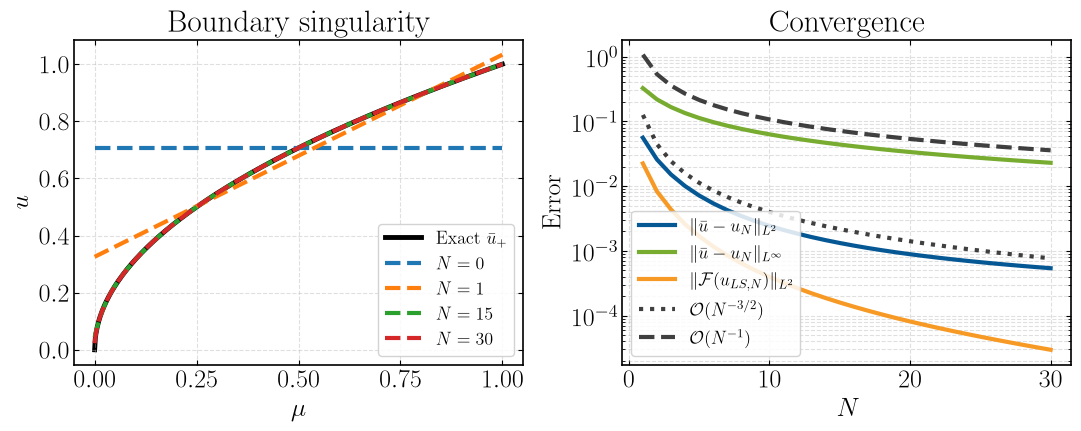

In [4]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]
solver = PCEGalerkin(rhs, jac, mu_bounds=(0.0, 1.0), state_dim=1, quad_order=2 * N_max + 1)
history = solver.continuation(N_max, u0=[1.0], return_history=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
mu_ex = np.linspace(0.0, 1.0, 600)
plot_2d(solver, [history[N] for N in plot_degrees], [(mu_ex, exact_upper(mu_ex))],
        branch_labels=[rf"$N={N}$" for N in plot_degrees], branch_lw=3.0,
        exact_lw=3.5, exact_label=r"Exact $\bar{u}_+$", title="Boundary singularity", ax=axes[0])
axes[0].legend(loc="lower right", framealpha=0.85)
plot_convergence(solver, history, exact_upper, ref_rates=[(r"$\mathcal{O}(N^{-3/2})$", ":", lambda N: N**(-1.5), "l2"), (r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "linf")], ax=axes[1])
plt.tight_layout()
plt.show()

### 2.3 Interior singularity

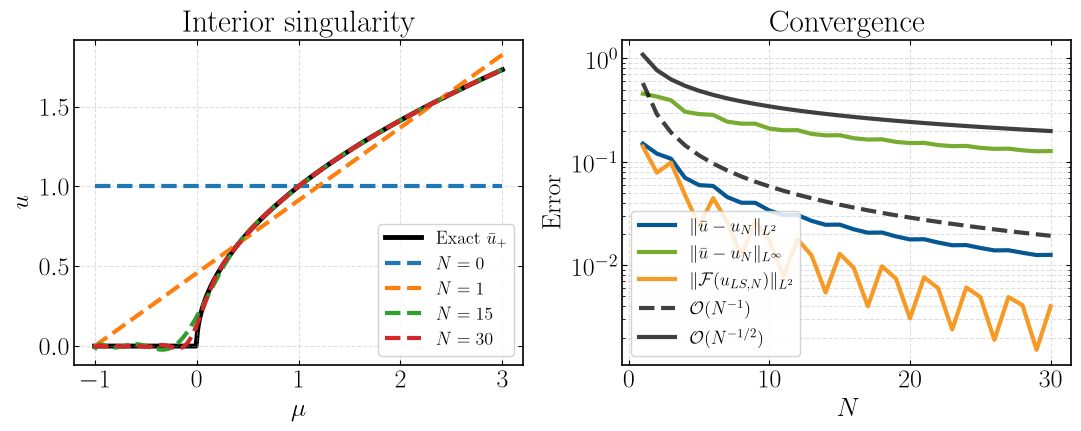

In [5]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]
solver = PCEGalerkin(rhs, jac, mu_bounds=(-1.0, 3.0), state_dim=1, quad_order=2 * N_max + 1)
history = solver.continuation(N_max, u0=[1.0], return_history=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
mu_ex = np.linspace(-1.0, 3.0, 600)
plot_2d(solver, [history[N] for N in plot_degrees], [(mu_ex, exact_upper(mu_ex))],
        branch_labels=[rf"$N={N}$" for N in plot_degrees], branch_lw=3.0,
        exact_lw=3.5, exact_label=r"Exact $\bar{u}_+$", title="Interior singularity", ax=axes[0])
axes[0].legend(loc="lower right", framealpha=0.85)
plot_convergence(solver, history, exact_upper, ref_rates=[(r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "l2"), (r"$\mathcal{O}(N^{-1/2})$", "-", lambda N: N**(-0.5), "linf")], ax=axes[1])
plt.tight_layout()
plt.show()